## EECE5644 Homework 5

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import multivariate_normal as mvn

RS = 42
np.random.seed(RS)
plt.rcParams.update({"figure.figsize": (6, 4), "axes.grid": True, "figure.dpi": 110})

## P5.1 Optimal Bayes classifier

**(c) Bayes classifier - empirical error**

In [2]:
def bayes_predict(X, mu0, mu1, S0, S1, prior1=0.5):
    llr = mvn.logpdf(X, mu1, S1) - mvn.logpdf(X, mu0, S0)
    return (llr > np.log((1 - prior1) / prior1)).astype(int)

mu0, mu1 = np.array([0., 0.]), np.array([2., 1.])
Sigma = np.array([[2., .5], [.5, 1.]])
n = 1000
rng = np.random.default_rng(RS)
X = np.vstack([rng.multivariate_normal(mu0, Sigma, n), rng.multivariate_normal(mu1, Sigma, n)])
y = np.r_[np.zeros(n), np.ones(n)].astype(int)

yhat = bayes_predict(X, mu0, mu1, Sigma, Sigma)
emp = np.mean(yhat != y)

d = mu1 - mu0
delta = np.sqrt(d @ np.linalg.solve(Sigma, d))
theo = stats.norm.sf(delta / 2)
se = np.sqrt(theo * (1 - theo) / len(y))
print(f"Delta = {delta:.4f}, theoretical Pe = {theo:.4f}")
print(f"Empirical Pe = {emp:.4f}  (standard error ~{se:.4f}, difference = {(emp - theo) / se:+.2f} SE)")

Delta = 1.5119, theoretical Pe = 0.2248
Empirical Pe = 0.2360  (standard error ~0.0093, difference = +1.19 SE)


**(d) Dataset visualization**

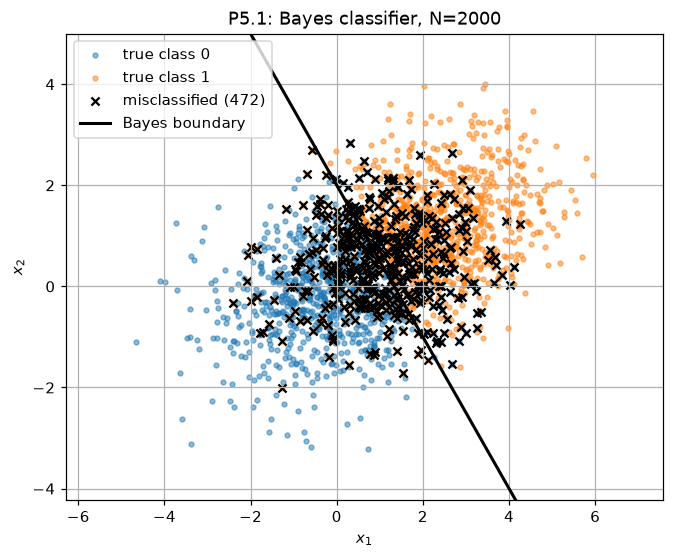

In [ ]:
w = np.linalg.solve(Sigma, d)
b = 0.5 * w @ (mu0 + mu1)
x1 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200)
x2 = (b - w[0] * x1) / w[1]

fig, ax = plt.subplots(figsize=(7, 5.5))
for c, col in [(0, "tab:blue"), (1, "tab:orange")]:
    ax.scatter(X[y == c, 0], X[y == c, 1], s=10, c=col, alpha=.5, label=f"true class {c}")
mis = yhat != y
ax.scatter(X[mis, 0], X[mis, 1], marker="x", c="k", s=28, label=f"misclassified ({mis.sum()})")
ax.plot(x1, x2, "k-", lw=2, label="Bayes boundary")
ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("P5.1: Bayes classifier, N=2000")
ax.legend(); plt.show()

## P5.2 Naive Bayes Classifier

**(a) Dataset description**

In [ ]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
Xb, yb = bc.data, bc.target
names = dict(enumerate(bc.target_names))
counts = pd.Series(yb).map(names).value_counts()
print(counts, "\nproportions:\n", (counts / len(yb)).round(3))
desc = pd.DataFrame(Xb, columns=bc.feature_names).describe().T[["mean", "std", "min", "max"]]
desc

benign       357
malignant    212
Name: count, dtype: int64 
proportions:
 benign       0.627
malignant    0.373
Name: count, dtype: float64


,mean,std,min,max
mean radius,14.127292,3.524049,6.981000,28.11000
mean texture,19.289649,4.301036,9.710000,39.28000
mean perimeter,91.969033,24.298981,43.790000,188.50000
mean area,654.889104,351.914129,143.500000,2501.00000
mean smoothness,0.096360,0.014064,0.052630,0.16340
mean compactness,0.104341,0.052813,0.019380,0.34540
mean concavity,0.088799,0.079720,0.000000,0.42680
mean concave points,0.048919,0.038803,0.000000,0.20120
mean symmetry,0.181162,0.027414,0.106000,0.30400
mean fractal dimension,0.062798,0.007060,0.049960,0.09744


**(b) Gaussian Naive Bayes Classifier**

GNB training accuracy: 0.9420035149384886
mean radius      mean perimeter     0.997855
worst radius     worst perimeter    0.993708
mean radius      mean area          0.987357
mean perimeter   mean area          0.986507
worst radius     worst area         0.984015
worst perimeter  worst area         0.977578
radius error     perimeter error    0.972794
mean perimeter   worst perimeter    0.970387
dtype: float64


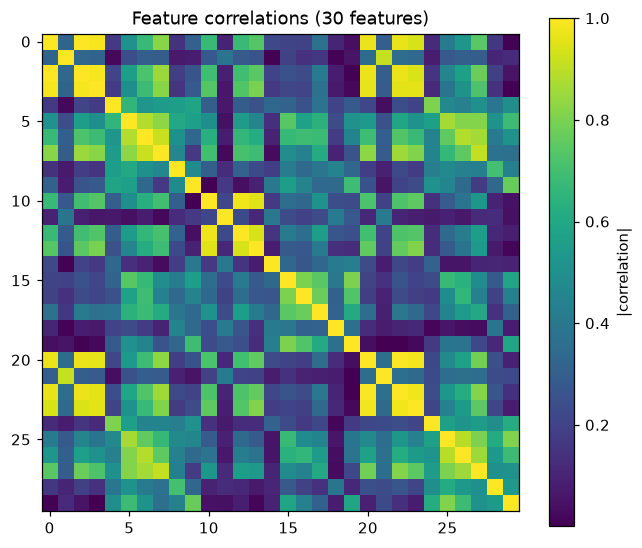

In [ ]:
from sklearn.naive_bayes import GaussianNB, BernoulliNB

gnb = GaussianNB().fit(Xb, yb)
print("GNB training accuracy:", gnb.score(Xb, yb))

corr = pd.DataFrame(Xb, columns=bc.feature_names).corr().abs()
top = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False).head(8)
print(top)
plt.figure(figsize=(7, 6)); plt.imshow(corr, cmap="viridis"); plt.colorbar(label="|correlation|")
plt.title("Feature correlations (30 features)"); plt.grid(False); plt.show()

**(c) GNB Evaluation**

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv10 = StratifiedKFold(10, shuffle=True, random_state=RS)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def summarize(model, X, y, cv):
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    k = cv.get_n_splits(); t = stats.t.ppf(.975, k - 1)
    rows = {}
    for m in scoring:
        v = res["test_" + m]; half = t * v.std(ddof=1) / np.sqrt(k)
        rows[m] = (v.mean(), v.mean() - half, v.mean() + half)
    return pd.DataFrame(rows, index=["mean", "ci_low", "ci_high"]).T

tab_gnb = summarize(GaussianNB(), Xb, yb, cv10)
tab_gnb.round(4)

,mean,ci_low,ci_high
accuracy,0.9368,0.9138,0.9598
precision,0.9379,0.9054,0.9704
recall,0.9665,0.9403,0.9927
f1,0.9509,0.9337,0.9680
roc_auc,0.9889,0.9825,0.9953


**(d) Gaussian NB vs Bernoulli NB**

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline

class MedianBinarizer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.med_ = np.median(X, axis=0); return self
    def transform(self, X):
        return (X > self.med_).astype(float)

tab_bnb = summarize(make_pipeline(MedianBinarizer(), BernoulliNB()), Xb, yb, cv10)
cmp = pd.concat({"GaussianNB": tab_gnb["mean"], "BernoulliNB (median-binarised)": tab_bnb["mean"]}, axis=1)
cmp.round(4)

,GaussianNB,BernoulliNB (median-binarised)
accuracy,0.9368,0.9139
precision,0.9379,0.9549
recall,0.9665,0.9076
f1,0.9509,0.9298
roc_auc,0.9889,0.9725


## P5.3 k-NN

**(b) Wine Quality Dataset**

(1599, 11) good fraction: 0.535
    k  train_acc  val_acc  val_std
0   1     1.0000   0.7623   0.0341
1   3     0.8610   0.7292   0.0359
2   5     0.8086   0.7223   0.0276
3   7     0.7928   0.7179   0.0207
4  11     0.7824   0.7298   0.0171
5  15     0.7700   0.7342   0.0246
6  21     0.7624   0.7354   0.0151
7  31     0.7505   0.7242   0.0170
k* = 1


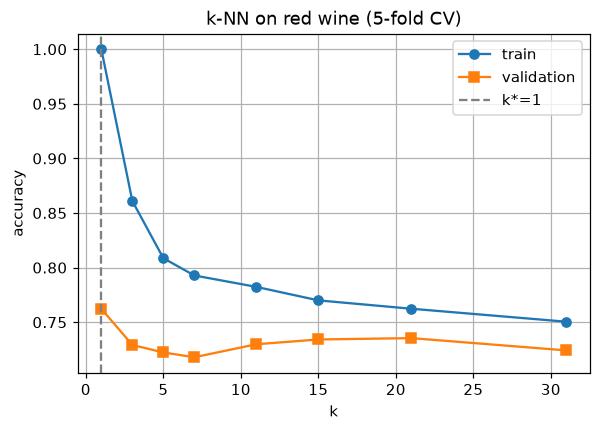

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate, cross_val_predict, cross_val_score, StratifiedKFold

wine = pd.read_csv("winequality-red.csv", sep=";")
Xw = wine.drop(columns="quality").values
yw = (wine["quality"] >= 6).astype(int).values
print(Xw.shape, "good fraction:", yw.mean().round(3))

cv5 = StratifiedKFold(5, shuffle=True, random_state=RS)
ks = [1, 3, 5, 7, 11, 15, 21, 31]
rows = []
for k in ks:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    r = cross_validate(pipe, Xw, yw, cv=cv5, return_train_score=True)
    rows.append((k, r["train_score"].mean(), r["test_score"].mean(), r["test_score"].std()))
res = pd.DataFrame(rows, columns=["k", "train_acc", "val_acc", "val_std"])
k_star = int(res.loc[res["val_acc"].idxmax(), "k"])
print(res.round(4)); print("k* =", k_star)

plt.plot(res.k, res.train_acc, "o-", label="train"); plt.plot(res.k, res.val_acc, "s-", label="validation")
plt.axvline(k_star, color="gray", ls="--", label=f"k*={k_star}")
plt.xlabel("k"); plt.ylabel("accuracy"); plt.title("k-NN on red wine (5-fold CV)"); plt.legend(); plt.show()

**(c) Confusion matrix at k**

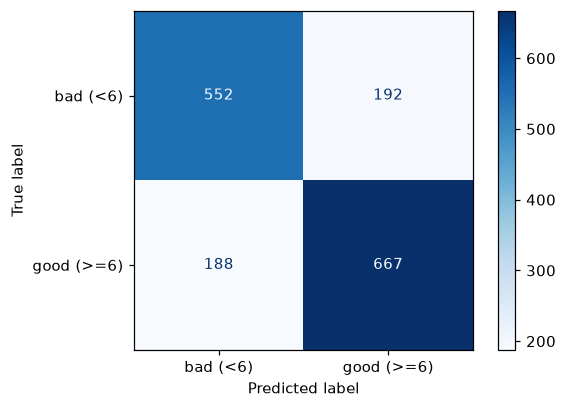

              precision    recall  f1-score   support

    bad (<6)       0.75      0.74      0.74       744
  good (>=6)       0.78      0.78      0.78       855

    accuracy                           0.76      1599
   macro avg       0.76      0.76      0.76      1599
weighted avg       0.76      0.76      0.76      1599



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

best = make_pipeline(StandardScaler(), KNeighborsClassifier(k_star))
pred = cross_val_predict(best, Xw, yw, cv=cv5)
cm = confusion_matrix(yw, pred)
ConfusionMatrixDisplay(cm, display_labels=["bad (<6)", "good (>=6)"]).plot(cmap="Blues"); plt.grid(False); plt.show()
print(classification_report(yw, pred, target_names=["bad (<6)", "good (>=6)"]))

**(d) Distance metric comparison at k**

In [ ]:
metrics = {"Manhattan (p=1)": dict(metric="minkowski", p=1), "Euclidean (p=2)": dict(metric="minkowski", p=2), "Chebyshev (p=inf)": dict(metric="chebyshev")}
out = {}
for name, kw in metrics.items():
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(k_star, **kw))
    s = cross_val_score(pipe, Xw, yw, cv=cv5)
    out[name] = (s.mean(), s.std())
pd.DataFrame(out, index=["mean_acc", "std"]).T.round(4)

,mean_acc,std
Manhattan (p=1),0.7586,0.0413
Euclidean (p=2),0.7623,0.0341
Chebyshev (p=inf),0.7504,0.0288


## P5.4 LDA

**(b) LDA and QDA on Iris**

=== LDA ===
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30

=== QDA ===
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



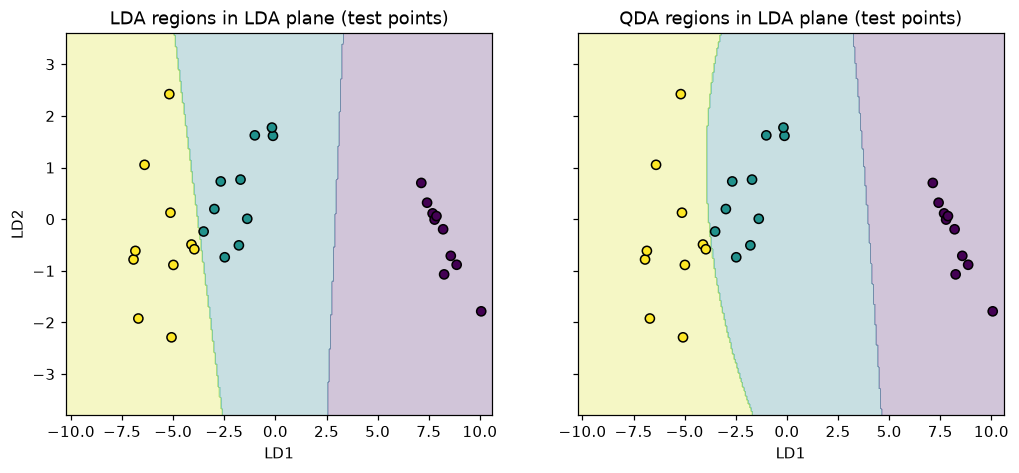

In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.metrics import classification_report

iris = load_iris()
Xi, yi = iris.data, iris.target
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=.2, stratify=yi, random_state=RS)

for name, model in [("LDA", LDA()), ("QDA", QDA())]:
    model.fit(Xtr, ytr)
    print(f"=== {name} ===")
    print(classification_report(yte, model.predict(Xte), target_names=iris.target_names, digits=3))

lda2 = LDA(n_components=2).fit(Xtr, ytr)
Ztr, Zte = lda2.transform(Xtr), lda2.transform(Xte)
gx, gy = np.meshgrid(np.linspace(Ztr[:, 0].min() - 1, Ztr[:, 0].max() + 1, 300),
                     np.linspace(Ztr[:, 1].min() - 1, Ztr[:, 1].max() + 1, 300))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, clf) in zip(axes, [("LDA", LDA()), ("QDA", QDA())]):
    clf.fit(Ztr, ytr)
    zz = clf.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, zz, alpha=.25, cmap="viridis")
    sc = ax.scatter(Zte[:, 0], Zte[:, 1], c=yte, cmap="viridis", edgecolor="k")
    ax.set_title(f"{name} regions in LDA plane (test points)"); ax.set_xlabel("LD1"); ax.grid(False)
axes[0].set_ylabel("LD2"); plt.show()

**(c) 1-D LDA projection histograms**

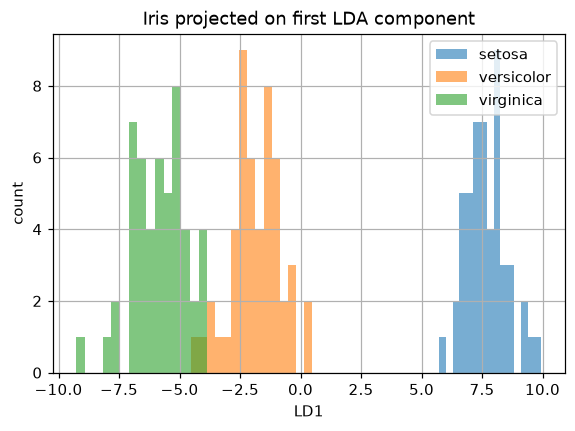

explained variance ratio of LD1, LD2: [0.9912126 0.0087874]


In [12]:
lda1 = LDA(n_components=1).fit(Xi, yi)
z = lda1.transform(Xi)[:, 0]
for c, nm in enumerate(iris.target_names):
    plt.hist(z[yi == c], bins=15, alpha=.6, label=nm)
plt.xlabel("LD1"); plt.ylabel("count"); plt.title("Iris projected on first LDA component"); plt.legend(); plt.show()
print("explained variance ratio of LD1, LD2:", LDA(n_components=2).fit(Xi, yi).explained_variance_ratio_)

# P5.6 Decision trees: criteria and pruning

**(a) Comparing impurity measures**

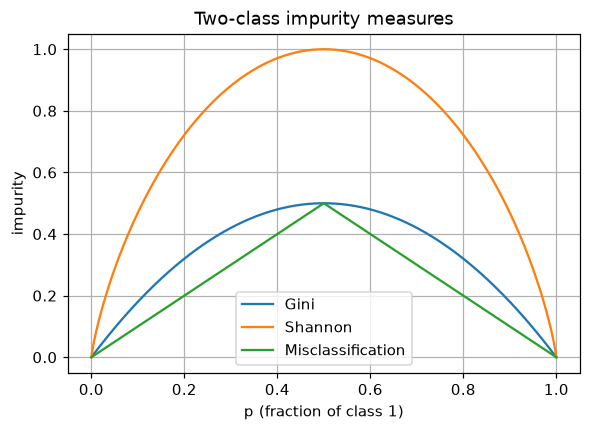

In [14]:
p = np.linspace(1e-6, 1 - 1e-6, 500)
G = 2 * p * (1 - p)
H = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
E = 1 - np.maximum(p, 1 - p)
plt.plot(p, G, label="Gini"); plt.plot(p, H, label="Shannon"); plt.plot(p, E, label="Misclassification")
plt.xlabel("p (fraction of class 1)"); plt.ylabel("impurity"); plt.title("Two-class impurity measures"); plt.legend(); plt.show()

**(b) Heart Disease Dataset**

rows before dropping missing: 303
rows used: 297 positive fraction: 0.461
  max_depth  train_acc  cv_acc  cv_std
0         2     0.7733  0.7005  0.0521
1         4     0.8848  0.7471  0.0763
2         6     0.9641  0.7374  0.0326
3         8     0.9925  0.7338  0.0538
4      None     1.0000  0.7406  0.0567


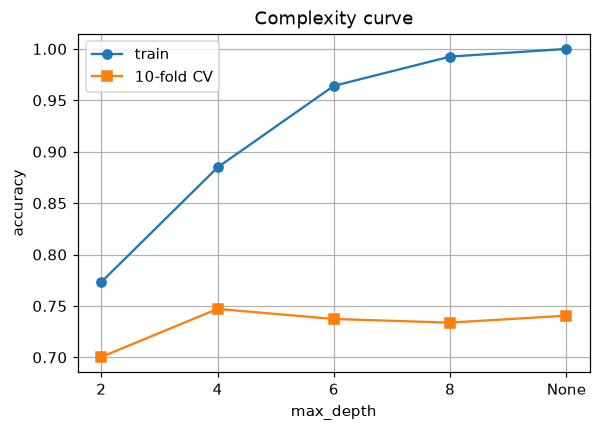

In [18]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","target"]
heart = pd.read_csv("processed.cleveland.csv", header=None, names=cols, na_values="?")
print("rows before dropping missing:", len(heart))
heart = heart.dropna()
Xh = heart.drop(columns="target").values
yh = (heart["target"] > 0).astype(int).values
print("rows used:", len(heart), "positive fraction:", yh.mean().round(3))

cv10 = StratifiedKFold(10, shuffle=True, random_state=RS)
depths = [2, 4, 6, 8, None]
rows = []
for dpt in depths:
    r = cross_validate(DecisionTreeClassifier(max_depth=dpt, criterion="gini", random_state=RS), Xh, yh, cv=cv10, return_train_score=True)
    rows.append((str(dpt), r["train_score"].mean(), r["test_score"].mean(), r["test_score"].std()))
dres = pd.DataFrame(rows, columns=["max_depth", "train_acc", "cv_acc", "cv_std"])
print(dres.round(4))
xs = np.arange(len(depths))
plt.plot(xs, dres.train_acc, "o-", label="train"); plt.plot(xs, dres.cv_acc, "s-", label="10-fold CV")
plt.xticks(xs, dres.max_depth); plt.xlabel("max_depth"); plt.ylabel("accuracy")
plt.title("Complexity curve"); plt.legend(); plt.show()

**(c) Tree Structure**

best depth: 4


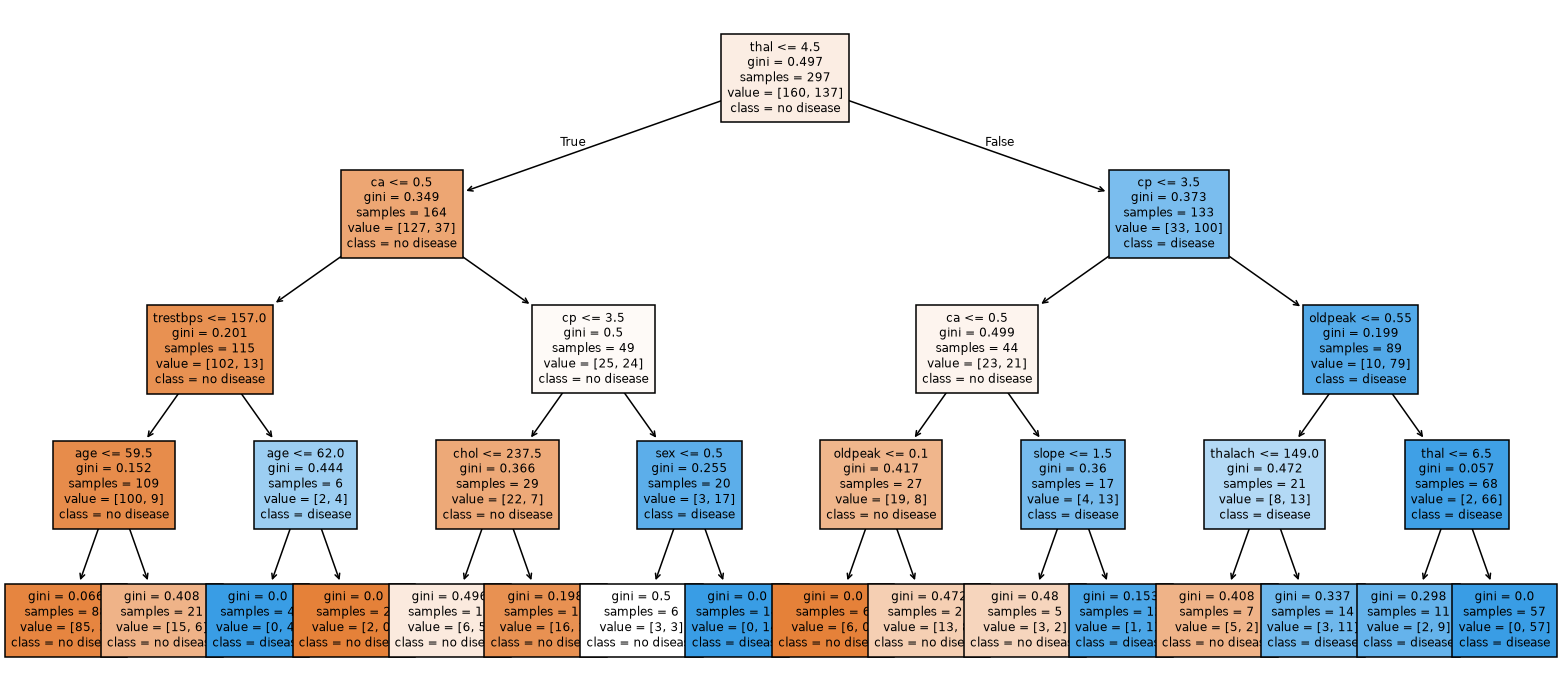

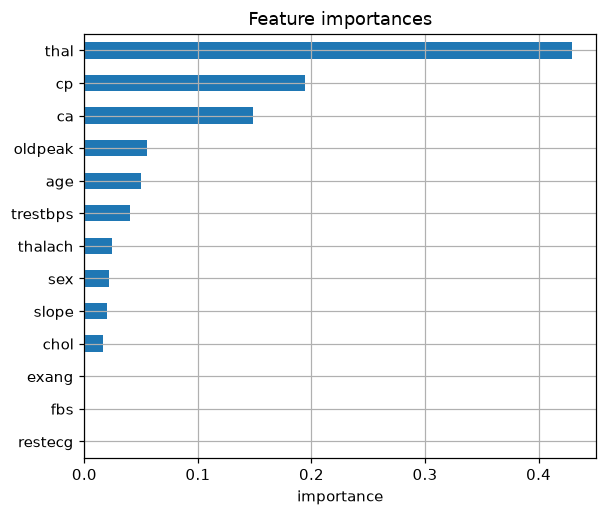

two most discriminative features: ['thal', 'cp']


In [17]:
best_depth = depths[int(dres["cv_acc"].idxmax())]
print("best depth:", best_depth)
clf = DecisionTreeClassifier(max_depth=best_depth, criterion="gini", random_state=RS).fit(Xh, yh)
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(clf, max_depth=4, feature_names=cols[:-1], class_names=["no disease", "disease"], filled=True, fontsize=8, ax=ax)
plt.show()

imp = pd.Series(clf.feature_importances_, index=cols[:-1]).sort_values()
imp.plot.barh(figsize=(6, 5)); plt.xlabel("importance"); plt.title("Feature importances"); plt.show()
print("two most discriminative features:", list(imp.index[-2:][::-1]))

**(d) Cost-complexity pruning**

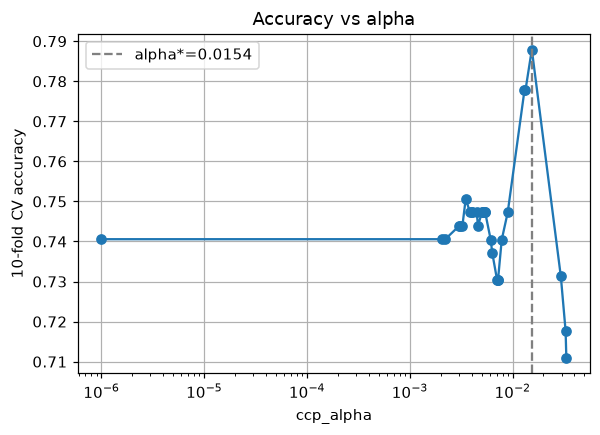

,unpruned,pruned
cv_acc,0.7406,0.7879
leaves,57.0000,5.0000
depth,11.0000,3.0000


In [19]:
path = DecisionTreeClassifier(criterion="gini", random_state=RS).cost_complexity_pruning_path(Xh, yh)
alphas = np.unique(path.ccp_alphas)[:-1]
rows = []
for a in alphas:
    m = DecisionTreeClassifier(criterion="gini", ccp_alpha=a, random_state=RS)
    s = cross_val_score(m, Xh, yh, cv=cv10)
    full = m.fit(Xh, yh)
    rows.append((a, s.mean(), s.std(), full.get_n_leaves(), full.get_depth()))
ares = pd.DataFrame(rows, columns=["alpha", "cv_acc", "cv_std", "leaves", "depth"])
a_star = ares.loc[ares["cv_acc"].idxmax(), "alpha"]

plt.semilogx(ares.alpha + 1e-6, ares.cv_acc, "o-"); plt.axvline(a_star + 1e-6, color="gray", ls="--", label=f"alpha*={a_star:.4f}")
plt.xlabel("ccp_alpha"); plt.ylabel("10-fold CV accuracy"); plt.title("Accuracy vs alpha"); plt.legend(); plt.show()

un = DecisionTreeClassifier(criterion="gini", random_state=RS)
pr = DecisionTreeClassifier(criterion="gini", ccp_alpha=a_star, random_state=RS)
tab = pd.DataFrame({
    "unpruned": [cross_val_score(un, Xh, yh, cv=cv10).mean(), un.fit(Xh, yh).get_n_leaves(), un.get_depth()],
    "pruned": [cross_val_score(pr, Xh, yh, cv=cv10).mean(), pr.fit(Xh, yh).get_n_leaves(), pr.get_depth()]},
    index=["cv_acc", "leaves", "depth"])
tab.round(4)

# P5.7 Logistic regression vs LDA (Pima)

**(a) Pima Indians Dataset, 70/30 split**

In [22]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)

pima = pd.read_csv("diabetes.csv")
Xp = pima.drop(columns="Outcome").values.astype(float); yp = pima["Outcome"].values
Xp[:, 1:6][Xp[:, 1:6] == 0] = np.nan
print(Xp.shape, "positive fraction:", yp.mean().round(3))

Xtr, Xte, ytr, yte = train_test_split(Xp, yp, test_size=.3, stratify=yp, random_state=RS)
print("train positives:", ytr.mean().round(3), " test positives:", yte.mean().round(3))

(768, 8) positive fraction: 0.349
train positives: 0.348  test positives: 0.351


**(b) LDA and L2 logistic regression fit**

In [23]:
models = {
    "LDA (empirical priors)": make_pipeline(SimpleImputer(strategy="median"), LDA()),
    "LDA (priors 0.5/0.5)": make_pipeline(SimpleImputer(strategy="median"), LDA(priors=[.5, .5])),
}
for m in models.values():
    m.fit(Xtr, ytr)

lr_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(penalty="l2", max_iter=2000))
grid = GridSearchCV(lr_pipe, {"logisticregression__C": np.logspace(-3, 2, 20)}, cv=StratifiedKFold(5, shuffle=True, random_state=RS), scoring="roc_auc").fit(Xtr, ytr)
print("best C:", grid.best_params_["logisticregression__C"])
models["Logistic regression (L2)"] = grid.best_estimator_

def evaluate(m):
    proba = m.predict_proba(Xte)[:, 1]; pred = m.predict(Xte)
    return dict(accuracy=accuracy_score(yte, pred), balanced_acc=balanced_accuracy_score(yte, pred), auc_roc=roc_auc_score(yte, proba), avg_precision=average_precision_score(yte, proba))

pd.DataFrame({k: evaluate(m) for k, m in models.items()}).T.round(4)

best C: 4.832930238571752


,accuracy,balanced_acc,auc_roc,avg_precision
LDA (empirical priors),0.7359,0.6831,0.8347,0.7172
LDA (priors 0.5/0.5),0.7532,0.7333,0.8347,0.7172
Logistic regression (L2),0.7446,0.6954,0.8359,0.7192


**(c) ROC and Precision-Recall plots**

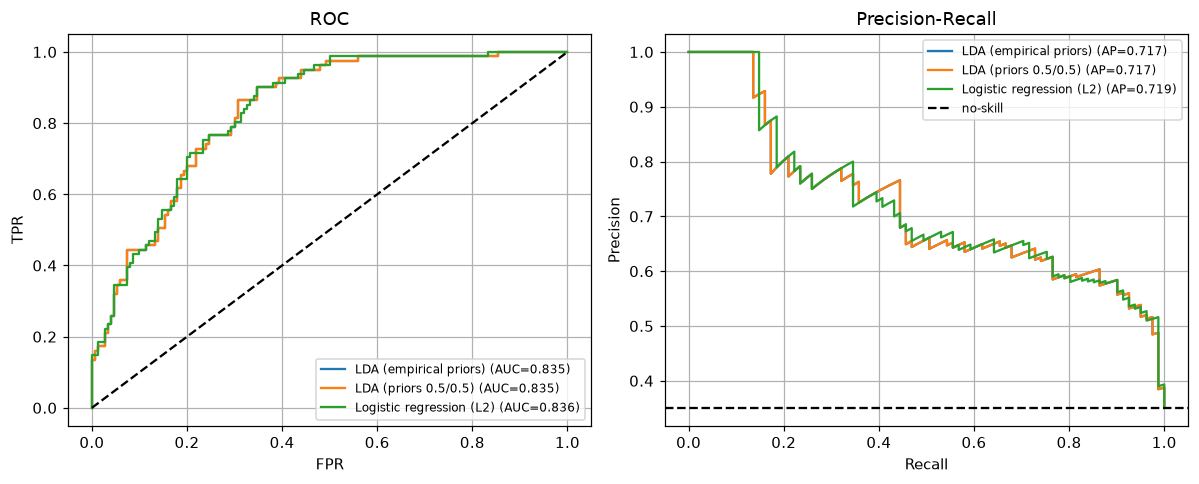

In [24]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
for name, m in models.items():
    proba = m.predict_proba(Xte)[:, 1]
    f, t, _ = roc_curve(yte, proba); a1.plot(f, t, label=f"{name} (AUC={roc_auc_score(yte, proba):.3f})")
    pr_, rc_, _ = precision_recall_curve(yte, proba); a2.plot(rc_, pr_, label=f"{name} (AP={average_precision_score(yte, proba):.3f})")
a1.plot([0, 1], [0, 1], "k--"); a1.set_xlabel("FPR"); a1.set_ylabel("TPR"); a1.set_title("ROC"); a1.legend(fontsize=8)
a2.axhline(yte.mean(), color="k", ls="--", label="no-skill"); a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title("Precision-Recall"); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

## P5.8 Performance measures and threshold analysis

**(c) Threshold sweep for logistic regression**

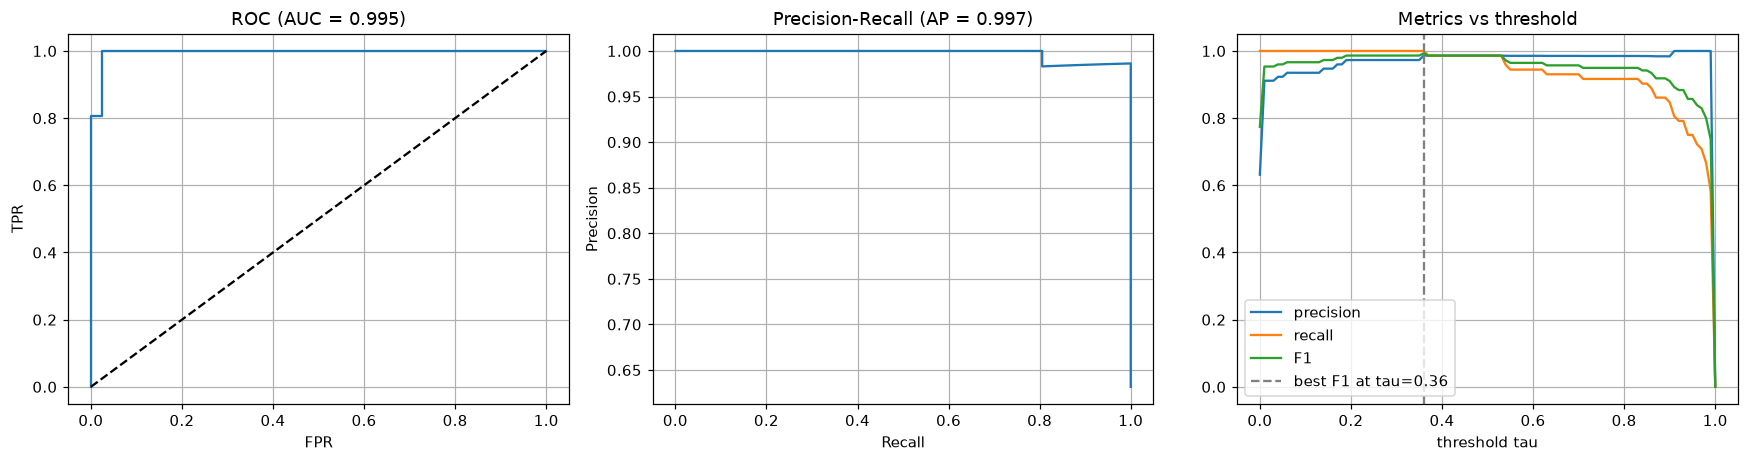

F1-maximising threshold: tau = 0.36, F1 = 0.9931


In [28]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, precision_score, recall_score, f1_score

Xb, yb = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=.2, stratify=yb, random_state=RS)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
proba = lr.predict_proba(Xte)[:, 1]

fpr, tpr, _ = roc_curve(yte, proba); roc_auc = auc(fpr, tpr)
prec, rec, _ = precision_recall_curve(yte, proba); ap = average_precision_score(yte, proba)
taus = np.linspace(0, 1, 101)
P = [precision_score(yte, proba >= t, zero_division=0) for t in taus]
R = [recall_score(yte, proba >= t, zero_division=0) for t in taus]
F = [f1_score(yte, proba >= t, zero_division=0) for t in taus]
t_best = taus[int(np.argmax(F))]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title(f"ROC (AUC = {roc_auc:.3f})"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
ax[1].plot(rec, prec); ax[1].set_title(f"Precision-Recall (AP = {ap:.3f})"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[2].plot(taus, P, label="precision"); ax[2].plot(taus, R, label="recall"); ax[2].plot(taus, F, label="F1")
ax[2].axvline(t_best, color="gray", ls="--", label=f"best F1 at tau={t_best:.2f}"); ax[2].set_xlabel("threshold tau"); ax[2].legend(); ax[2].set_title("Metrics vs threshold")
plt.tight_layout(); plt.show()
print(f"F1-maximising threshold: tau = {t_best:.2f}, F1 = {max(F):.4f}")

**(d) Reliability diagram**

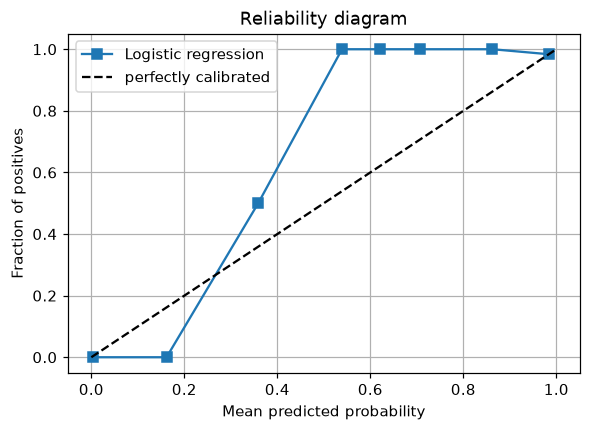

test points per bin: [37  3  0  2  0  3  1  1  5 62]


In [29]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(yte, proba, n_bins=10)
plt.plot(prob_pred, prob_true, "s-", label="Logistic regression"); plt.plot([0, 1], [0, 1], "k--", label="perfectly calibrated")
plt.xlabel("Mean predicted probability"); plt.ylabel("Fraction of positives"); plt.title("Reliability diagram"); plt.legend(); plt.show()
print("test points per bin:", np.histogram(proba, bins=10, range=(0, 1))[0])

# P5.9 Bias-variance and learning curves

**(a) MNIST Dataset**

In [31]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, learning_curve
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

pool_X, test_X, pool_y, test_y = train_test_split(X, y, test_size=1000, stratify=y, random_state=RS)
B, N = 50, 500

def bias_var(make_model, seed=RS):
    rng = np.random.default_rng(seed)
    preds = np.zeros((B, len(test_y)))
    for b in range(B):
        idx = rng.choice(len(pool_y), N, replace=True)
        preds[b] = make_model().fit(pool_X[idx], pool_y[idx]).predict(test_X)
    ybar = preds.mean(axis=0)
    return np.mean((ybar - test_y) ** 2), preds.var(axis=0).mean()     # bias^2, variance (1/B normalisation)

bv = {"kNN (k=5)": bias_var(lambda: KNeighborsClassifier(5)),
      "Decision tree": bias_var(lambda: DecisionTreeClassifier(random_state=RS))}
pd.DataFrame(bv, index=["bias^2", "variance"]).T.round(4)

,bias^2,variance
kNN (k=5),0.0189,0.0195
Decision tree,0.0288,0.0602


**(b) Learning curves**

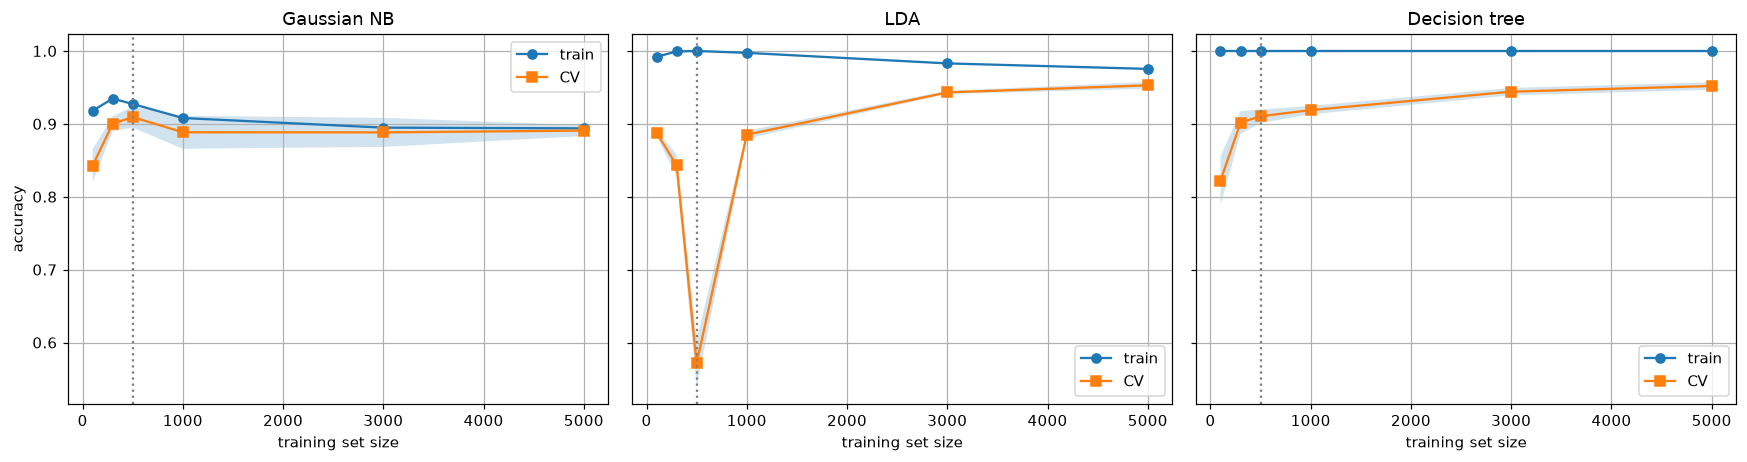

In [33]:
sizes = [100, 300, 500, 1000, 3000, 5000]
cvl = StratifiedKFold(5, shuffle=True, random_state=RS)
curve_models = {"Gaussian NB": GaussianNB(var_smoothing=1e-3), "LDA": LDA(), "Decision tree": DecisionTreeClassifier(random_state=RS)}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, (name, est) in zip(axes, curve_models.items()):
    ts, tr_sc, va_sc = learning_curve(est, X, y, train_sizes=sizes, cv=cvl, scoring="accuracy", n_jobs=-1, shuffle=True, random_state=RS)
    ax.plot(ts, tr_sc.mean(1), "o-", label="train"); ax.plot(ts, va_sc.mean(1), "s-", label="CV")
    ax.fill_between(ts, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=.2)
    ax.axvline(500, color="gray", ls=":"); ax.set_title(name); ax.set_xlabel("training set size"); ax.legend()
axes[0].set_ylabel("accuracy"); plt.tight_layout(); plt.show()

**(c) Nested Cross Validation**

In [34]:
candidates = {
    "LDA": (LDA(), {}),
    "Tree": (DecisionTreeClassifier(random_state=RS), {"max_depth": [2, 4, 6, 8, 12, None]}),
    "GNB": (GaussianNB(var_smoothing=1e-3), {"var_smoothing": [1e-4, 1e-3, 1e-2]}),
}
outer = StratifiedKFold(5, shuffle=True, random_state=RS)
inner = StratifiedKFold(3, shuffle=True, random_state=RS)

nested_acc, chosen = [], []
for tr, te in outer.split(X, y):
    best = None
    for name, (est, grid_) in candidates.items():
        gs = GridSearchCV(clone(est), grid_, cv=inner, n_jobs=-1).fit(X[tr], y[tr])
        if best is None or gs.best_score_ > best[1]:
            best = (name, gs.best_score_, gs)
    chosen.append(best[0]); nested_acc.append(best[2].score(X[te], y[te]))
nested_err = 1 - np.mean(nested_acc)

non_nested = {name: GridSearchCV(clone(est), grid_, cv=outer, n_jobs=-1).fit(X, y).best_score_
              for name, (est, grid_) in candidates.items()}
non_nested_err = 1 - max(non_nested.values())

print("models chosen per outer fold:", chosen)
print(f"Nested CV error estimate     : {nested_err:.4f}")
print(f"Non-nested (single 5-fold)   : {non_nested_err:.4f}")

models chosen per outer fold: ['Tree', 'Tree', 'Tree', 'Tree', 'Tree']
Nested CV error estimate     : 0.0369
Non-nested (single 5-fold)   : 0.0364   (expected to be lower = optimistic)
